In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
# Load cleaned datasets

productivity_df = pd.read_csv("../excel/productivity clean.csv")
downtime_df = pd.read_csv("../excel/Downtime clean.csv")
factors_df = pd.read_csv("../excel/Factors clean.csv")
products_df = pd.read_csv("../excel/products clean.csv")

print("All datasets loaded successfully!")



All datasets loaded successfully!


In [5]:
print("productivity:",productivity_df.shape)
print("Downtime:", downtime_df.shape)
print("Factors:", factors_df.shape)
print("Products:", products_df.shape)


productivity: (31, 14)
Downtime: (38, 13)
Factors: (12, 3)
Products: (5, 4)


In [6]:
# Display column names and data types

print("========== PRODUCTIVITY DATASET ==========")
print(productivity_df.info())

print("\n========== DOWNTIME DATASET ==========")
print(downtime_df.info())

print("\n========== FACTORS DATASET ==========")
print(factors_df.info())

print("\n========== PRODUCTS DATASET ==========")
print(products_df.info())

========== PRODUCTIVITY DATASET ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       31 non-null     object 
 1   Product                    31 non-null     object 
 2   Batch                      31 non-null     int64  
 3   Operator                   31 non-null     object 
 4   Start Time                 31 non-null     object 
 5   End Time                   31 non-null     object 
 6   Production Duration        31 non-null     int64  
 7   Flavor                     31 non-null     object 
 8   Size                       31 non-null     object 
 9   Min Batch Time             31 non-null     int64  
 10  Total Downtime (Minutes)   31 non-null     int64  
 11  Excess Time                31 non-null     int64  
 12  Production Efficiency (%)  31 non-null     float64
 13  Shifts   

In [7]:
# Preview the first 5 rows of each dataset

print("========== PRODUCTIVITY ==========")
display(productivity_df.head())

print("========== DOWNTIME ==========")
display(downtime_df.head())

print("========== FACTORS ==========")
display(factors_df.head())

print("========== PRODUCTS ==========")
display(products_df.head())

========== PRODUCTIVITY ==========


,Date,Product,Batch,Operator,Start Time,End Time,Production Duration,Flavor,Size,Min Batch Time,Total Downtime (Minutes),Excess Time,Production Efficiency (%),Shifts
0,29-08-2024,OR-600,422111,Mac,11:50:00,14:05:00,135,Orange,600 ml,60,75,0,44.44,Morning Shift
1,29-08-2024,LE-600,422112,Mac,14:05:00,15:45:00,100,Lemon lime,600 ml,60,40,0,60.00,Morning Shift
2,29-08-2024,LE-600,422113,Mac,15:45:00,17:35:00,110,Lemon lime,600 ml,60,50,0,54.55,Morning Shift
3,29-08-2024,LE-600,422114,Mac,17:35:00,19:15:00,100,Lemon lime,600 ml,60,40,0,60.00,Evening Shift
4,29-08-2024,LE-600,422115,Charlie,19:15:00,20:39:00,84,Lemon lime,600 ml,60,24,0,71.43,Evening Shift


========== DOWNTIME ==========


,Batch,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9,Factor 10,Factor 11,Factor 12,total downtime
0,422111,60,0,0,0,0,15,0,0,0,0,0,75
1,422112,20,0,0,0,0,0,20,0,0,0,0,40
2,422113,50,0,0,0,0,0,0,0,0,0,0,50
3,422114,0,0,25,0,15,0,0,0,0,0,0,40
4,422115,0,0,0,0,0,0,0,0,24,0,0,24


========== FACTORS ==========


,Factor,Description,Operator Error
0,1,Emergency stop,No
1,2,Batch change,Yes
2,3,Labeling error,No
3,4,Inventory shortage,No
4,5,Product spill,Yes


========== PRODUCTS ==========


,Product,Flavor,Size,Min batch time
0,OR-600,Orange,600 ml,60
1,LE-600,Lemon lime,600 ml,60
2,CO-600,Cola,600 ml,60
3,DC-600,Diet Cola,600 ml,60
4,CO-2L,Cola,2 L,98


In [8]:
# Missing value check

print("========== PRODUCTIVITY ==========")
print(productivity_df.isnull().sum())

print("\n========== DOWNTIME ==========")
print(downtime_df.isnull().sum())

print("\n========== FACTORS ==========")
print(factors_df.isnull().sum())

print("\n========== PRODUCTS ==========")
print(products_df.isnull().sum())

========== PRODUCTIVITY ==========
Date                         0
Product                      0
Batch                        0
Operator                     0
Start Time                   0
End Time                     0
Production Duration          0
Flavor                       0
Size                         0
Min Batch Time               0
Total Downtime (Minutes)     0
Excess Time                  0
Production Efficiency (%)    0
Shifts                       0
dtype: int64

========== DOWNTIME ==========
Batch             0
Factor 2          0
Factor 3          0
Factor 4          0
Factor 5          0
Factor 6          0
Factor 7          0
Factor 8          0
Factor 9          0
Factor 10         0
Factor 11         0
Factor 12         0
total downtime    0
dtype: int64

========== FACTORS ==========
Factor            0
Description       0
Operator Error    0
dtype: int64

========== PRODUCTS ==========
Product           0
Flavor            0
Size              0
Min batch time   

In [9]:
# Duplicate row check

print("Productivity duplicates:", productivity_df.duplicated().sum())
print("Downtime duplicates:",downtime_df.duplicated().sum())
print("Factors duplicates:", factors_df.duplicated().sum())
print("Products duplicates:", products_df.duplicated().sum())

Productivity duplicates: 0
Downtime duplicates: 0
Factors duplicates: 0
Products duplicates: 0


In [10]:
# Statistical summary of numerical columns

print("========== PRODUCTIVITY ==========")
display(productivity_df.describe())

print("========== DOWNTIME ==========")
display(downtime_df.describe())

print("========== FACTORS ==========")
display(factors_df.describe())

print("========== PRODUCTS ==========")
display(products_df.describe())

========== PRODUCTIVITY ==========


,Batch,Production Duration,Min Batch Time,Total Downtime (Minutes),Excess Time,Production Efficiency (%)
count,31.000000,31.000000,31.000000,31.000000,31.0,31.000000
mean,422127.129032,102.580645,66.129032,36.451613,0.0,67.669677
std,10.947578,31.955985,14.207374,24.069121,0.0,15.272944
min,422111.000000,60.000000,60.000000,0.000000,0.0,44.440000
25%,422118.500000,80.000000,60.000000,20.000000,0.0,55.845000
50%,422126.000000,100.000000,60.000000,32.000000,0.0,66.670000
75%,422133.500000,116.000000,60.000000,51.000000,0.0,75.190000
max,422148.000000,205.000000,98.000000,107.000000,0.0,100.000000


========== DOWNTIME ==========


,Batch,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9,Factor 10,Factor 11,Factor 12,total downtime
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,422129.500000,4.210526,1.105263,5.921053,1.500000,8.736842,6.684211,3.815789,0.447368,1.289474,0.868421,1.947368,36.526316
std,11.113055,13.075990,4.757864,11.367050,5.259483,15.682120,11.128501,10.010414,2.757764,4.758537,3.032892,4.942630,23.135017
min,422111.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,422120.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000
50%,422129.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,33.500000
75%,422138.750000,0.000000,0.000000,0.000000,0.000000,14.750000,15.000000,0.000000,0.000000,0.000000,0.000000,0.000000,51.500000
max,422148.000000,60.000000,22.000000,43.000000,22.000000,60.000000,30.000000,44.000000,17.000000,24.000000,13.000000,20.000000,107.000000


========== FACTORS ==========


,Factor
count,12.000000
mean,6.500000
std,3.605551
min,1.000000
25%,3.750000
50%,6.500000
75%,9.250000
max,12.000000


========== PRODUCTS ==========


,Min batch time
count,5.000000
mean,67.600000
std,16.994117
min,60.000000
25%,60.000000
50%,60.000000
75%,60.000000
max,98.000000


In [11]:
# Check unique categorical values

print("========== PRODUCTS ==========")
print("Products:")
print(productivity_df["Product"].unique())

print("\nFlavors:")
print(productivity_df["Flavor"].unique())

print("\nSizes:")
print(productivity_df["Size"].unique())

print("\nOperators:")
print(productivity_df["Operator"].unique())

print("\nShifts:")
print(productivity_df["Shifts"].unique())

========== PRODUCTS ==========
Products:
['OR-600' 'LE-600' 'CO-600' 'DC-600' 'CO-2L']

Flavors:
['Orange' 'Lemon lime' 'Cola' 'Diet Cola']

Sizes:
['600 ml' '2 L']

Operators:
['Mac' 'Charlie' 'Dee' 'Dennis']

Shifts:
['Morning Shift' 'Evening Shift' 'Night Shift']


In [12]:
# Frequency of categorical values

print("========== PRODUCT ==========")
display(productivity_df["Product"].value_counts())

print("========== FLAVOR ==========")
display(productivity_df["Flavor"].value_counts())

print("========== OPERATOR ==========")
display(productivity_df["Operator"].value_counts())

print("========== SHIFT ==========")
display(productivity_df["Shifts"].value_counts())

========== PRODUCT ==========


CO-600    15
LE-600     6
CO-2L      5
DC-600     4
OR-600     1
Name: Product, dtype: int64

========== FLAVOR ==========


Cola          20
Lemon lime     6
Diet Cola      4
Orange         1
Name: Flavor, dtype: int64

========== OPERATOR ==========


Charlie    11
Mac         8
Dee         7
Dennis      5
Name: Operator, dtype: int64

========== SHIFT ==========


Morning Shift    15
Evening Shift    12
Night Shift       4
Name: Shifts, dtype: int64

In [13]:
# ============================================
# MANUFACTURING KPI CALCULATIONS
# ============================================

total_downtime = productivity_df["Total Downtime (Minutes)"].sum()

avg_efficiency = productivity_df["Production Efficiency (%)"].mean()

avg_production_duration = productivity_df["Production Duration"].mean()

total_excess_time = productivity_df["Excess Time"].sum()

total_batches = productivity_df["Batch"].nunique()

avg_downtime_per_batch = productivity_df["Total Downtime (Minutes)"].mean()

min_efficiency = productivity_df["Production Efficiency (%)"].min()

max_efficiency = productivity_df["Production Efficiency (%)"].max()


# ============================================
# DISPLAY RESULTS
# ============================================

print("========== MANUFACTURING KPI SUMMARY ==========")

print(f"Total Downtime                : {total_downtime:,.0f} minutes")
print(f"Average Production Efficiency : {avg_efficiency:.2f}%")
print(f"Average Production Duration   : {avg_production_duration:.2f} minutes")
print(f"Total Excess Time             : {total_excess_time:,.2f} minutes")
print(f"Total Batches                 : {total_batches}")
print(f"Average Downtime per Batch    : {avg_downtime_per_batch:.2f} minutes")
print(f"Minimum Efficiency            : {min_efficiency:.2f}%")
print(f"Maximum Efficiency            : {max_efficiency:.2f}%")

========== MANUFACTURING KPI SUMMARY ==========
Total Downtime                : 1,130 minutes
Average Production Efficiency : 67.67%
Average Production Duration   : 102.58 minutes
Total Excess Time             : 0.00 minutes
Total Batches                 : 31
Average Downtime per Batch    : 36.45 minutes
Minimum Efficiency            : 44.44%
Maximum Efficiency            : 100.00%


In [14]:
# ============================================
# KPI SUMMARY DATAFRAME
# ============================================

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Production Duration",
        "Total Downtime",
        "Average Production Efficiency",
        "Average Production Duration",
        "Total Excess Time",
        "Total Batches",
        "Average Downtime per Batch",
        "Minimum Efficiency",
        "Maximum Efficiency"
    ],
    
    "Value": [
        productivity_df["Production Duration"].sum(),
        productivity_df["Total Downtime (Minutes)"].sum(),
        productivity_df["Production Efficiency (%)"].mean(),
        productivity_df["Production Duration"].mean(),
        productivity_df["Excess Time"].sum(),
        productivity_df["Batch"].nunique(),
        productivity_df["Total Downtime (Minutes)"].mean(),
        productivity_df["Production Efficiency (%)"].min(),
        productivity_df["Production Efficiency (%)"].max()
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Production Duration,3180.000000
1,Total Downtime,1130.000000
2,Average Production Efficiency,67.669677
3,Average Production Duration,102.580645
4,Total Excess Time,0.000000
5,Total Batches,31.000000
6,Average Downtime per Batch,36.451613
7,Minimum Efficiency,44.440000
8,Maximum Efficiency,100.000000


In [15]:
# ============================================
# ANALYSIS 2: DOWNTIME BY PRODUCT
# ============================================

product_downtime = (
    productivity_df
    .groupby("Product")["Total Downtime (Minutes)"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_downtime.columns = ["Product", "Total Downtime"]

display(product_downtime)

,Product,Total Downtime
0,CO-600,494
1,CO-2L,277
2,LE-600,169
3,DC-600,115
4,OR-600,75


In [16]:
product_downtime["Downtime %"] = (
    product_downtime["Total Downtime"]
    / product_downtime["Total Downtime"].sum()
    * 100
)

display(product_downtime)

,Product,Total Downtime,Downtime %
0,CO-600,494,43.716814
1,CO-2L,277,24.513274
2,LE-600,169,14.955752
3,DC-600,115,10.176991
4,OR-600,75,6.637168


In [17]:
# ============================================
# ANALYSIS 3: OPERATOR EFFICIENCY
# ============================================

operator_efficiency = (
    productivity_df
    .groupby("Operator")["Production Efficiency (%)"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

operator_efficiency.columns = ["Operator", "Average Efficiency"]

display(operator_efficiency)

,Operator,Average Efficiency
0,Charlie,70.972727
1,Dee,70.118571
2,Dennis,64.034000
3,Mac,63.257500


In [18]:
# ============================================
# ANALYSIS 4: DOWNTIME BY OPERATOR
# ============================================

operator_downtime = (
    productivity_df
    .groupby("Operator")["Total Downtime (Minutes)"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

operator_downtime.columns = ["Operator", "Total Downtime"]

display(operator_downtime)

,Operator,Total Downtime
0,Charlie,384
1,Mac,332
2,Dee,207
3,Dennis,207


In [19]:
# ============================================
# ANALYSIS 5: SHIFT PERFORMANCE
# ============================================

shift_analysis = (
    productivity_df
    .groupby("Shifts")
    .agg(
        Total_Batches=("Batch", "nunique"),
        Total_Downtime=("Total Downtime (Minutes)", "sum"),
        Average_Efficiency=("Production Efficiency (%)", "mean"),
        Average_Duration=("Production Duration", "mean")
    )
    .reset_index()
)

shift_analysis = shift_analysis.sort_values(
    "Average_Efficiency",
    ascending=False
)

display(shift_analysis)

,Shifts,Total_Batches,Total_Downtime,Average_Efficiency,Average_Duration
0,Evening Shift,12,414,71.6175,104.000000
1,Morning Shift,15,559,65.9460,102.333333
2,Night Shift,4,157,62.2900,99.250000


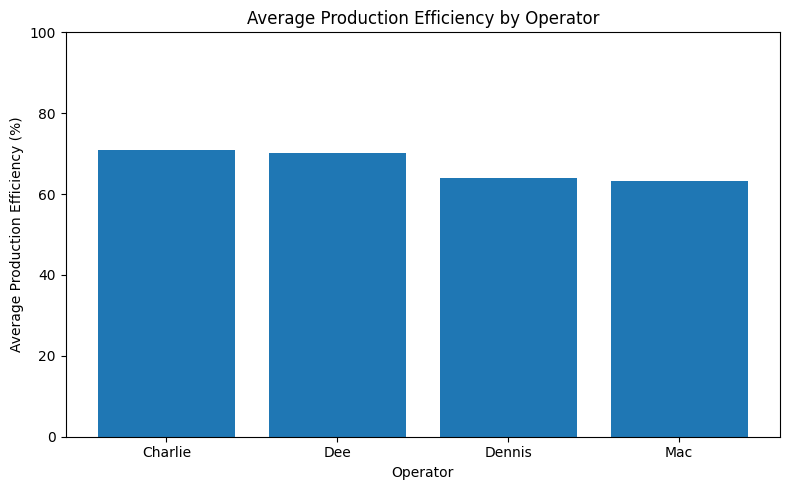

In [20]:
import matplotlib.pyplot as plt

# ============================================
# MATPLOTLIB: OPERATOR EFFICIENCY
# ============================================

plt.figure(figsize=(8, 5))

plt.bar(
    operator_efficiency["Operator"],
    operator_efficiency["Average Efficiency"]
)

plt.title("Average Production Efficiency by Operator")
plt.xlabel("Operator")
plt.ylabel("Average Production Efficiency (%)")

plt.ylim(0, 100)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

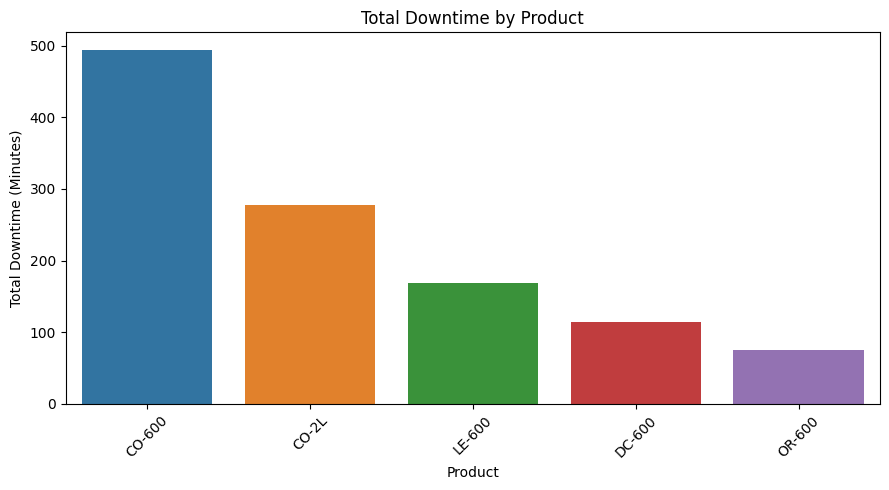

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# ============================================
# SEABORN: PRODUCT DOWNTIME
# ============================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=product_downtime,
    x="Product",
    y="Total Downtime"
)

plt.title("Total Downtime by Product")
plt.xlabel("Product")
plt.ylabel("Total Downtime (Minutes)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
# ============================================
# DOWNTIME FACTOR ANALYSIS
# ============================================

# Calculate total downtime for each factor
factor_totals = downtime_df.drop(columns=["Batch"]).sum()

factor_analysis = (
    factor_totals
    .sort_values(ascending=False)
    .reset_index()
)

factor_analysis.columns = ["Factor", "Total Downtime"]

display(factor_analysis)

,Factor,Total Downtime
0,total downtime,1388
1,Factor 6,332
2,Factor 7,254
3,Factor 4,225
4,Factor 2,160
5,Factor 8,145
6,Factor 12,74
7,Factor 5,57
8,Factor 10,49
9,Factor 3,42


In [23]:
# Percentage contribution of each downtime factor

factor_analysis["Downtime %"] = (
    factor_analysis["Total Downtime"]
    / factor_analysis["Total Downtime"].sum()
    * 100

).round(2)

display(factor_analysis)

,Factor,Total Downtime,Downtime %
0,total downtime,1388,50.00
1,Factor 6,332,11.96
2,Factor 7,254,9.15
3,Factor 4,225,8.11
4,Factor 2,160,5.76
5,Factor 8,145,5.22
6,Factor 12,74,2.67
7,Factor 5,57,2.05
8,Factor 10,49,1.77
9,Factor 3,42,1.51


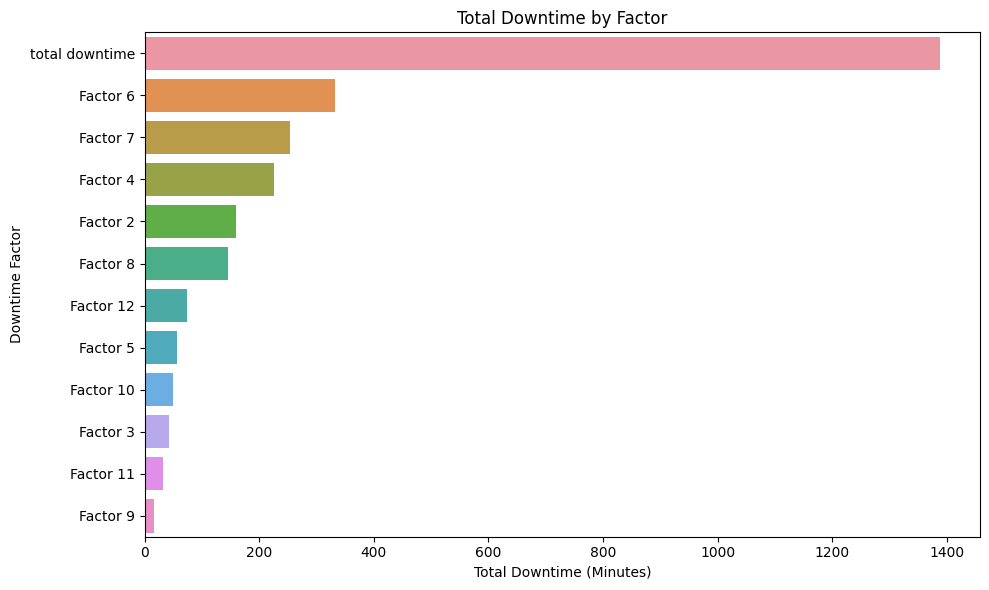

In [24]:
# ============================================
# SEABORN: DOWNTIME FACTOR ANALYSIS
# ============================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=factor_analysis,
    x="Total Downtime",
    y="Factor"
)

plt.title("Total Downtime by Factor")
plt.xlabel("Total Downtime (Minutes)")
plt.ylabel("Downtime Factor")

plt.tight_layout()
plt.show()

In [25]:
# ============================================
# DOWNTIME VS PRODUCTION EFFICIENCY
# ============================================

correlation = productivity_df[
    ["Total Downtime (Minutes)", "Production Efficiency (%)"]
].corr()

display(correlation)

,Total Downtime (Minutes),Production Efficiency (%)
Total Downtime (Minutes),1.000000,-0.897318
Production Efficiency (%),-0.897318,1.000000


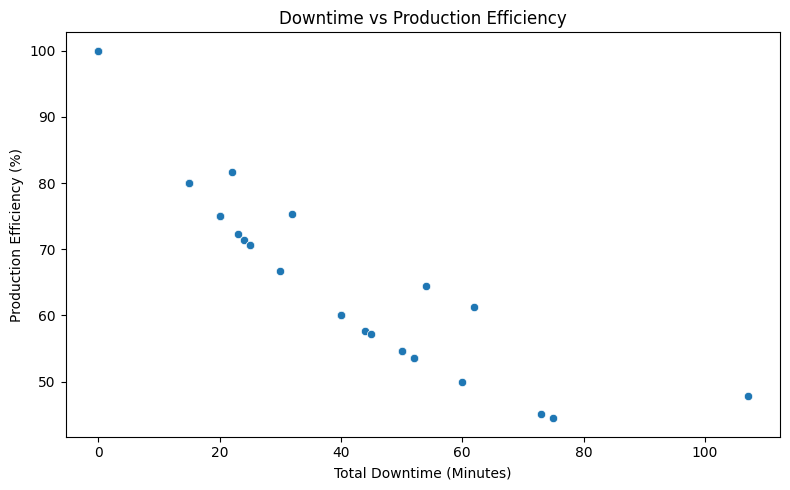

In [26]:
# ============================================
# SCATTER PLOT
# ============================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=productivity_df,
    x="Total Downtime (Minutes)",
    y="Production Efficiency (%)"
)

plt.title("Downtime vs Production Efficiency")
plt.xlabel("Total Downtime (Minutes)")
plt.ylabel("Production Efficiency (%)")

plt.tight_layout()
plt.show()

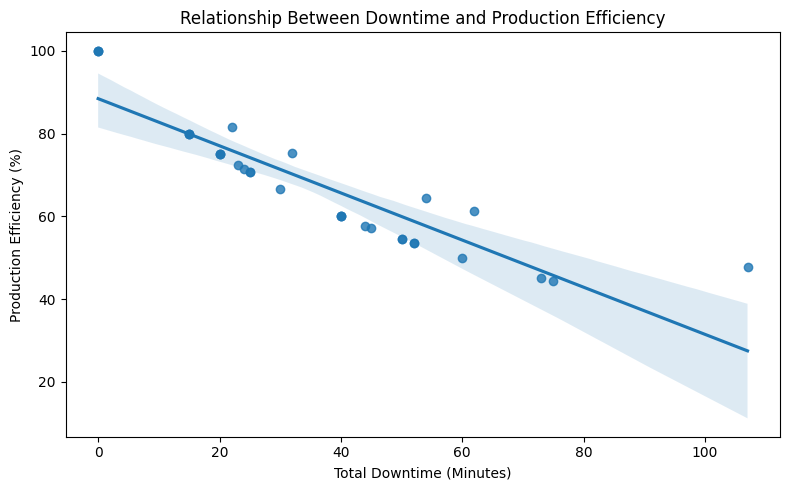

In [27]:
# ============================================
# REGRESSION / TREND LINE
# ============================================

plt.figure(figsize=(8, 5))

sns.regplot(
    data=productivity_df,
    x="Total Downtime (Minutes)",
    y="Production Efficiency (%)"
)

plt.title("Relationship Between Downtime and Production Efficiency")
plt.xlabel("Total Downtime (Minutes)")
plt.ylabel("Production Efficiency (%)")

plt.tight_layout()
plt.show()

In [28]:
# ==========================================
# ML: Downtime Risk Prediction
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("ML libraries imported successfully")

ML libraries imported successfully


In [29]:
# Calculate median downtime
median_downtime = productivity_df["Total Downtime (Minutes)"].median()

print("Median Downtime:", median_downtime)

Median Downtime: 32.0


In [30]:
# Create a copy for ML
ml_df = productivity_df.copy()

# Create target variable
ml_df["Downtime_Risk"] = (
    ml_df["Total Downtime (Minutes)"] > median_downtime
).astype(int)

# Display distribution
print(ml_df["Downtime_Risk"].value_counts())

0    16
1    15
Name: Downtime_Risk, dtype: int64


In [31]:
features = [
    "Product",
    "Operator",
    "Shifts",
    "Size",
    "Min Batch Time"
]

X = ml_df[features]
y = ml_df["Downtime_Risk"]

In [32]:
X = pd.get_dummies(
    X,
    columns=["Product", "Operator", "Shifts", "Size"],
    drop_first=True
)

print("Features prepared successfully")
print(X.head())

Features prepared successfully
   Min Batch Time  Product_CO-600  Product_DC-600  Product_LE-600  \
0              60               0               0               0   
1              60               0               0               1   
2              60               0               0               1   
3              60               0               0               1   
4              60               0               0               1   

   Product_OR-600  Operator_Dee  Operator_Dennis  Operator_Mac  \
0               1             0                0             1   
1               0             0                0             1   
2               0             0                0             1   
3               0             0                0             1   
4               0             0                0             0   

   Shifts_Morning Shift  Shifts_Night Shift  Size_600 ml  
0                     1                   0            1  
1                     1                

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 21
Testing samples: 10


In [34]:
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully")

Decision Tree model trained successfully


In [35]:
y_pred = model.predict(X_test)

print("Predictions completed")

Predictions completed


In [36]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Low Downtime", "High Downtime"]
    )
)

Model Accuracy: 50.0 %

Classification Report:
               precision    recall  f1-score   support

 Low Downtime       0.50      0.60      0.55         5
High Downtime       0.50      0.40      0.44         5

     accuracy                           0.50        10
    macro avg       0.50      0.50      0.49        10
 weighted avg       0.50      0.50      0.49        10



In [37]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3 2]
 [3 2]]


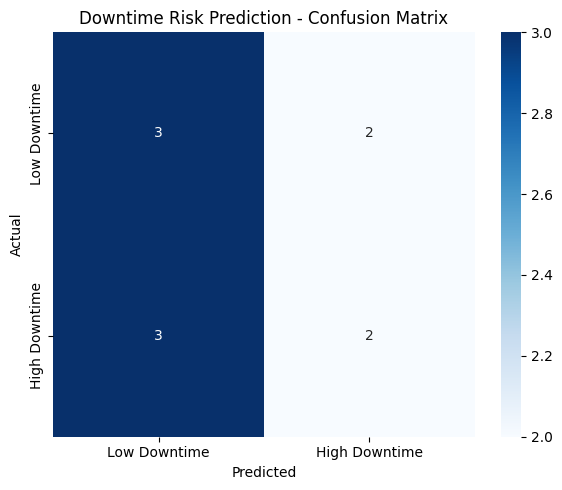

In [38]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Downtime", "High Downtime"],
    yticklabels=["Low Downtime", "High Downtime"]
)

plt.title("Downtime Risk Prediction - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

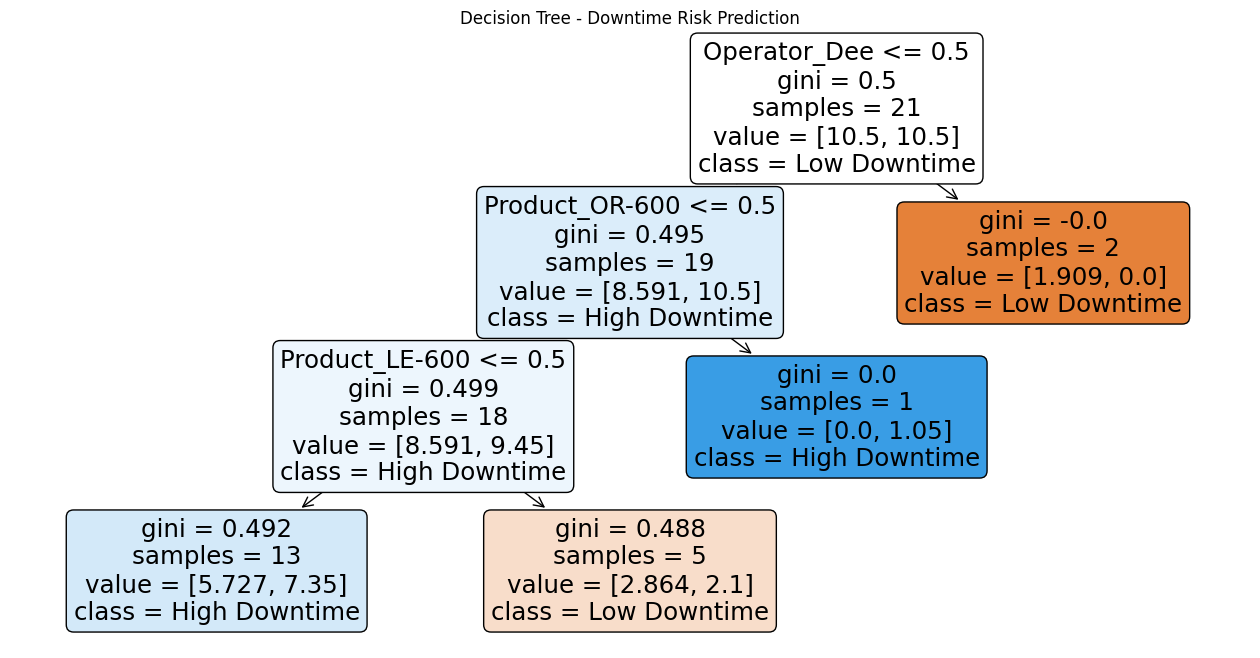

In [39]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Low Downtime", "High Downtime"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Downtime Risk Prediction")
plt.show()